# 개념 정리

### 7.5. LSTM

RNN의 기울기 소멸 문제를 해결하기 위해 LSTM이나 GRU 같은 방식 사용

#### 7.5.1. LSTM 구조

LTSM 순전파
- 망각 게이트(forget gate): 과거 정보를 어느 정도 기억할지 결정. 0과 1 사이의 출력 값을 가지는 h_t-1과 x_t를 입력 값으로 받아 계산한 값이 1이면 직전의 정보를 메모리에 유지, 계산한 값이 0이면 초기화.
- 입력 게이트(input gate): 현재 정보를 기억. 계산한 값이 1이면 입력 x_t가 들어올 수 있도록 허용, 계산한 값이 0이면 차단.
- 셀: 각 단계에 대한 은닉 노드(hidden node)를 메모리 셀이라고 함. 총합을 사용해 셀 값을 반영하고, 기울기 소멸 문제 해결. 망각 게이트와 입력 게이트의 이전 단계 셀 정보를 계산하여 현재 단계의 셀 상태(cell state)를 업데이트.
- 출력 게이트(output gate): 과거 정보와 현재 데이터를 사용해 뉴런 출력 결정. 이전 은닉 상태(hidden state)와 t번째 입력을 고려해 다음 은닉 상태 계산. 계산한 값이 1이면 의미 있는 결과로 최종 출력, 계산한 값이 0이면 해당 연산 출력을 하지 않음.

LSTM 역전파: 셀을 통해 수행하므로 중단 없는 기울기(uninterrupted gradient flow)라고도 함. 셀 단위로 오차가 전파되지만 셀 내부적으로는 오차가 입력으로도 전파됨.

#### 7.5.2. LSTM 셀 구현

gates = F.linear(input, w_ih, b_ih) + F.linear(hx, w_hh, b_hh)
- input: 입력층으로 입력되는 훈련 데이터셋의 피처 수
- w_ih: 입력층과 은닉층 사이의 가중치
- b_ih: 입력층과 은닉층 사이의 바이어스
- hx: 은닉층의 뉴런/유닉 개수(은닉층의 피처 수)
- w_hh: 은닉층과 은닉층 사이의 가중치
- b_hh: 은닉층과 은닉층 사이의 바이어스


ingate, forgetgate, cellgate, outgate = gates.chunk(4, 1)
- 첫 번째 파라미터: 텐서를 몇 개로 쪼갤지 설정
- 두 번째 파라미터: 어떤 차원을 기준으로 쪼갤지 결정. dim=1이므로 열 단위로 텐서 분할
- 네 개로 쪼개져서 각 게이트로 저장되므로 gates를 생성할 때 은닉층 뉴런/유닛에 4를 곱해줌.

현재 버전에서는 모든 텐서가 자동으로 Variable의 성질을 갖기 때문에 torch.autograd.Variable을 사용할 필요가 없음.

#### 7.5.3. LSTM 계층 구현

날짜 칼럼은 임베딩 처리가 어려운 경우가 많으나 인덱스로 처리하면 편리함.

plt.axvline(x=200, c='r', linestyle='--')
- 그래프의 축을 따라 수직선을 표현
- 첫 번째 파라미터: 어떤 지점에 수직선을 표현할지 지정
- c: 색상
- linestyle: 스타일
- 수평선은 axhline()을 사용

# 코드 필사

#### 7.5.2. LSTM 셀 구현

In [4]:
# 라이브러리 호출

import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.autograd import Variable
from torch.nn import Parameter
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda = True if torch.cuda.is_available() else False

Tensor = torch.cuda.FloatTensor if cuda else torch.FloatTensor

torch.manual_seed(125)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(125)

In [5]:
# 데이터 전처리

import torchvision.transforms as transforms

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (1.0,))
])

In [6]:
# 데이터셋 내려받기

from torchvision.datasets import MNIST

download_root = './data/MNIST_DATASET'
train_dataset = MNIST(download_root, transform=mnist_transform, train=True, download=True)
valid_dataset = MNIST(download_root, transform=mnist_transform, train=False, download=True)
test_dataset = MNIST(download_root, transform=mnist_transform, train=False, download=True)

In [7]:
# 데이터셋을 메모리로 가져오기

batch_size = 64
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(dataset=valid_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

In [8]:
# 변수 값 지정

batch_size = 100
n_iters = 6000
num_epochs = n_iters / (len(train_dataset) / batch_size)
num_epochs = int(num_epochs)

In [9]:
# LSTM 셀 네트워크 구축

class LSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size, bias=True):
        super(LSTMCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.bias = bias
        self.x2h = nn.Linear(input_size, 4 * hidden_size, bias=bias)
        self.h2h = nn.Linear(hidden_size, 4 * hidden_size, bias=bias)
        self.reset_parameters()

    def reset_parameters(self):
        std = 1.0 / math.sqrt(self.hidden_size)
        for w in self.parameters():
            w.data.uniform_(-std, std)

    def forward(self, x, hidden):
        hx, cx = hidden
        x = x.view(-1, x.size(1))

        gates = self.x2h(x) + self.h2h(hx)
        gates = gates.squeeze()
        ingate, forgetgate, cellgate, outgate = gates.chunk(4, 1)

        ingate = F.sigmoid(ingate) # 입력 게이트에 시그모이드 활성화 함수 적용
        forgetgate = F.sigmoid(forgetgate) # 망각 게이트에 시그모이드 활성화 함수 적용
        cellgate = F.tanh(cellgate)  # 셀 게이트에 탄젠트 활성화 함수 적용
        outgate = F.sigmoid(outgate) # 출력 게이트에 시그모이드 활성화 함수 적용

        cy = torch.mul(cx, forgetgate) + torch.mul(ingate, cellgate)
        hy = torch.mul(outgate, F.tanh(cy))
        return(hy, cy)

In [10]:
# LSTM 셀의 전반적인 네트워크

class LSTMModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
        super(LSTMModel, self).__init__()
        self.hidden_dim = hidden_dim # 은닉층의 뉴런/유닛 개수

        self.layer_dim = layer_dim
        self.lstm = LSTMCell(input_dim, hidden_dim, layer_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        if torch.cuda.is_available():
            h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda()) # 은닉 상태를 0으로 초기화
        else:
            h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

        if torch.cuda.is_available():
            c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda()) # 셀 상태를 0으로 초기화
        else:
            c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

        outs = []
        cn = c0[0, :, :] # 셀 상태에 대한 텐서
        hn = h0[0, :, :] # 은닉 상태에 대한 텐서

        for seq in range(x.size(1)): # LSTM 셀 계층을 반복하여 쌓아 올림
            hn, cn = self.lstm(x[:, seq, :], (hn, cn)) # 은닉 상태와 셀 상태를 LSTMCell에 적용한 결과를 다시 저장
            outs.append(hn)

        out = outs[-1].squeeze()
        out = self.fc(out)
        return out

In [11]:
# 옵티마이저와 손실 함수 지정

input_dim = 28
hidden_dim = 128
layer_dim = 1
output_dim = 10

model = LSTMModel(input_dim, hidden_dim, layer_dim, output_dim)
if torch.cuda.is_available():
    model.cuda()
criterion = nn.CrossEntropyLoss()
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [12]:
# 모델 학습 및 성능 확인

seq_dim = 28
loss_list = []
iter = 0
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        if torch.cuda.is_available():
            images = Variable(images.view(-1, seq_dim, input_dim).cuda())
            labels = Variable(labels.cuda())
        else:
            images = Variable(images.view(-1, seq_dim, input_dim))
            labels = Variable(labels)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        if torch.cuda.is_available():
            loss.cuda()

        loss.backward()
        optimizer.step()
        loss_list.append(loss.item())
        iter += 1

        if iter % 500 == 0:
            correct = 0
            total = 0
            for images, labels in valid_loader:
                if torch.cuda.is_available():
                    images = Variable(images.view(-1, seq_dim, input_dim).cuda())
                    labels = labels.cuda()
                else:
                    images = Variable(images.view(-1, seq_dim, input_dim))
                    labels = labels.to(device)

                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)
                if torch.cuda.is_available():
                    correct += (predicted.cpu() == labels.cpu()).sum()
                else:
                    correct += (predicted == labels).sum()

            accuracy = 100 * correct / total
            print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(), accuracy))

Iteration: 500. Loss: 2.237457752227783. Accuracy: 21.420000076293945
Iteration: 1000. Loss: 0.9419203400611877. Accuracy: 71.68000030517578
Iteration: 1500. Loss: 0.4356967806816101. Accuracy: 88.68000030517578
Iteration: 2000. Loss: 0.25007981061935425. Accuracy: 92.63999938964844
Iteration: 2500. Loss: 0.186321422457695. Accuracy: 94.55000305175781
Iteration: 3000. Loss: 0.08367566019296646. Accuracy: 96.19000244140625
Iteration: 3500. Loss: 0.07261523604393005. Accuracy: 96.5
Iteration: 4000. Loss: 0.02390708401799202. Accuracy: 97.12000274658203
Iteration: 4500. Loss: 0.04583405703306198. Accuracy: 96.9000015258789
Iteration: 5000. Loss: 0.08148844540119171. Accuracy: 96.7699966430664
Iteration: 5500. Loss: 0.12063965946435928. Accuracy: 97.19999694824219
Iteration: 6000. Loss: 0.013896778225898743. Accuracy: 97.80000305175781
Iteration: 6500. Loss: 0.026707401499152184. Accuracy: 97.7300033569336
Iteration: 7000. Loss: 0.021142348647117615. Accuracy: 97.69999694824219
Iteration: 

In [15]:
# 테스트 데이터셋을 이용한 모델 예측 성능 확인

def evaluate(model, val_iter):
    corrects, total, total_loss = 0, 0, 0
    model.eval()
    for images, labels in val_iter:
        if torch.cuda.is_available():
            images = Variable(images.view(-1, seq_dim, input_dim).cuda())
        else:
            images = Variable(images.view(-1, seq_dim, input_dim)).to(device)

        labels = labels.to(device)
        
        logit = model(images).to(device)
        loss = F.cross_entropy(logit, labels, reduction="sum")
        _, predicted = torch.max(logit.data, 1)  # logit.data 텐서에서 최댓값의 인덱스 반환
        total += labels.size(0)
        total_loss += loss.item()
        corrects += (predicted == labels).sum()

    avg_loss = total_loss / len(val_iter.dataset)
    avg_accuracy = corrects / total
    return avg_loss, avg_accuracy

In [16]:
# 모델 예측 성능 확인

test_loss, test_acc = evaluate(model, test_loader)
print("test Loss: %5.2f | Test Accuracy: %5.2f" % (test_loss, test_acc))

test Loss:  0.06 | Test Accuracy:  0.98


#### 7.5.3. LSTM 계층 구현

In [17]:
# 라이브러리 호출

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [18]:
# 데이터셋 가져오기

data = pd.read_csv('./data/SBUX.csv')
print(data.dtypes)

Date             str
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


In [19]:
# 날짜 칼럼을 인덱스로 사용

data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True) # date 칼럼을 인덱스로 사용

In [20]:
# 데이터 형식 변경

data['Volume'] = data['Volume'].astype(float)

In [21]:
# 훈련과 레이블 분리

X = data.iloc[:, :-1]
y = data.iloc[:, 5:6]
print(X)
print(y)

                  Open        High         Low       Close   Adj Close
Date                                                                  
2019-12-11   86.260002   86.870003   85.849998   86.589996   84.145752
2019-12-12   88.000000   88.889999   87.540001   88.209999   85.720032
2019-12-13   88.019997   88.790001   87.580002   88.669998   86.167046
2019-12-16   89.139999   89.300003   88.430000   88.779999   86.273941
2019-12-17   88.870003   88.970001   87.470001   88.129997   85.642288
...                ...         ...         ...         ...         ...
2020-12-04  101.349998  102.940002  101.070000  102.279999  101.442787
2020-12-07  102.010002  102.220001  100.690002  101.410004  100.579918
2020-12-08  100.370003  101.570000  100.010002  101.209999  100.381554
2020-12-09  101.940002  102.209999  100.099998  100.400002   99.578186
2020-12-10  103.510002  106.089996  102.750000  105.389999  104.527336

[253 rows x 5 columns]
                Volume
Date                  
2019-12

In [22]:
# 데이터 분포 조정

ms = MinMaxScaler() # 데이터의 모든 값이 0~1 사이에 존재하도록 분산 조정
ss = StandardScaler() # 데이터가 표준정규분포가 되도록 분산 조정

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]
X_test = X_ss[200:, :]

y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

print('Training Shape', X_train.shape, y_train.shape)
print('Testing Shape', X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Testing Shape (53, 5) (53, 1)


In [24]:
# 데이터셋의 형태 및 크기 조정

X_train_tensors = Variable(torch.Tensor(X_train)) # Variable로 감싸진 텐서는 .backward()가 호출될 때 자동으로 기울기가 계산
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(X_train_tensors, (X_train_tensors.shape[0], 1, X_train_tensors.shape[1]))
X_test_tensors_f = torch.reshape(X_test_tensors, (X_test_tensors.shape[0], 1, X_test_tensors.shape[1]))

print('Training Shape', X_train_tensors_f.shape, y_train_tensors.shape)
print('Testing Shape', X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Testing Shape torch.Size([53, 1, 5]) torch.Size([53, 1])


In [25]:
# LSTM 네트워크

class LSTM(nn.Module):
    def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
        super(LSTM, self).__init__()
        self.num_classes = num_classes # 클래스 개수
        self.num_layers = num_layers # LSTM 계층의 개수
        self.input_size = input_size # 입력 크기로 훈련 데이터셋의 칼럼 개수를 의미
        self.hidden_size = hidden_size # 은닉층의 뉴런 개수
        self.seq_length = seq_length # 시퀀스 길이

        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, num_layers=num_layers, batch_first=True) # LSTM 계층
        self.fc_1 = nn.Linear(hidden_size, 128) # 완전연결층
        self.fc = nn.Linear(128, num_classes) # 출력층
        self.relu = nn.ReLU()

    def forward(self, x):
        h_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size)) # 은닉 상태를 0으로 초기화
        c_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size)) # 셀 상태를 0으로 초기화
        output, (hn, cn) = self.lstm(x, (h_0, c_0)) # LSTM 계층에 은닉 상태와 셀 상태 적용
        hn = hn.view(-1, self.hidden_size) # 완전연결층 적용을 위해 데이터의 형태 조정(1차원으로 조정)
        out = self.relu(hn)
        out = self.fc_1(out)
        out = self.relu(out)
        out = self.fc(out)
        return out

In [26]:
# 변수 값 설정

num_epochs = 1000
learning_rate = 0.0001

input_size = 5 # 입력 데이터셋의 칼럼 개수
hidden_size = 2 # 은닉층의 뉴런/유닛 개수
num_layers = 1 # LSTM 계층의 개수

num_classes = 1 # 클래스 개수
model = LSTM(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1]) # LSTM 모델 학습

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [27]:
# 모델 학습

for epoch in range(num_epochs):
    outputs = model.forward(X_train_tensors_f)
    optimizer.zero_grad()
    loss = criterion(outputs, y_train_tensors)
    loss.backward()

    optimizer.step()
    if epoch % 100 == 0:
        print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.22602
Epoch: 100, loss: 0.06871
Epoch: 200, loss: 0.03774
Epoch: 300, loss: 0.03395
Epoch: 400, loss: 0.03218
Epoch: 500, loss: 0.03053
Epoch: 600, loss: 0.02901
Epoch: 700, loss: 0.02768
Epoch: 800, loss: 0.02639
Epoch: 900, loss: 0.02505


In [29]:
# 모델 예측 결과를 출력하기 위한 데이터 크기 재구성

df_x_ss = ss.transform(data.iloc[:, :-1]) # 데이터 정규화 (분포 조정)
df_y_ms = ms.transform(data.iloc[:, -1:]) # 데이터 정규화

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))
df_x_ss = torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

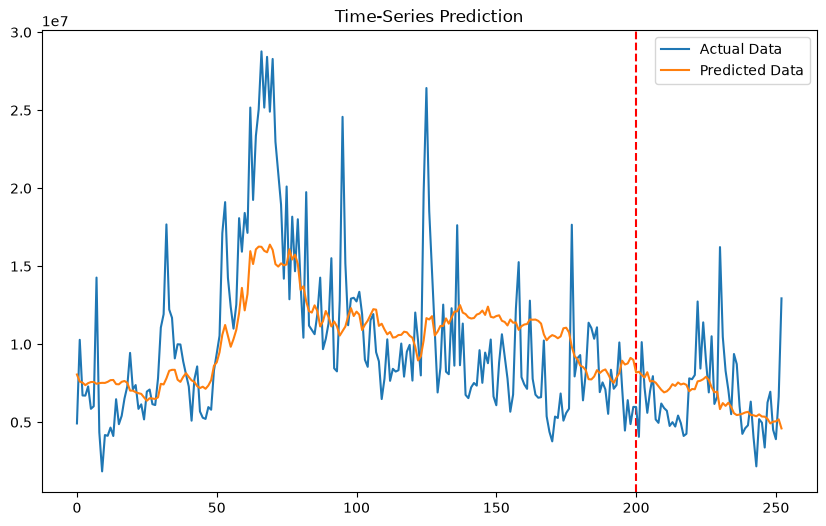

In [30]:
# 모델 예측 결과 출력

train_predict = model(df_x_ss)
predicted = train_predict.data.numpy()
label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted) # 모델 학습을 위해 전처리했던 것을 해제
label_y = ms.inverse_transform(label_y)
plt.figure(figsize=(10, 6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()